Poprawić jeszcze , endpoint=False) dla linspace. Przynajmniej sprawdzić.

In [1]:
import sys, inspect
import qss
import qss.distributions as d

print(sys.executable)
print(qss.__file__)
print(inspect.getsource(d.prepare_2D_lattice_data))

import numpy as np
from qss.distributions import prepare_2D_lattice_data

kx = np.array([0.0, np.pi])
ky = np.array([0.0, np.pi])

E0, _, _ = prepare_2D_lattice_data(kx, ky, t=-1.0, t_prim=0.0)
E1, _, _ = prepare_2D_lattice_data(kx, ky, t=-1.0, t_prim=0.25)

print("tp=0.0:\n", E0)
print("tp=0.25:\n", E1)
print("difference:\n", E1 - E0)

/home/piotr/Documents/github/quantum-statistics-solver/.venv/bin/python
/home/piotr/Documents/github/quantum-statistics-solver/.venv/lib/python3.11/site-packages/qss/__init__.py
def prepare_2D_lattice_data(
    kx: LatticeData,
    ky: LatticeData,
    t: float = -1.0,
    t_prim: float = 0.25,
) -> tuple[NDArray[np.floating], NDArray[np.floating], NDArray[np.floating]]:
    """
    Prepare 2D lattice data for a simple 2D tight-binding model.

    Parameters
    ----------
    kx : array-like or float
        x-component of wave vector
    ky : array-like or float
        y-component of wave vector
    t : float, optional
        Nearest-neighbor hopping parameter (default: -1.0)
    t_prim : float, optional
        Next-nearest-neighbor hopping parameter (default: 0.25)

    Returns
    -------
    tuple[np.ndarray, np.ndarray, np.ndarray]
        `(e_k, KX, KY)` where `e_k` is the energy dispersion (same shape as the
        meshgrid), and `KX`, `KY` are the meshgrid arrays of wave v

In [2]:
#%pip install seaborn
#import seaborn

# Entropy Calculation

In [3]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_theme(style="whitegrid")

from qss.solver_options import brent_defaults
from qss.chemical_potential import chemical_potential
from qss.entropy import entropy
## Przeładowanie bilbiotek pod testowanie zmian
#import importlib
#importlib.reload(sp)
#importlib.reload(qss.distributions)
from qss.distributions import prepare_2D_lattice_data, DistType
import tools.scientific_plot_v2 as sp
plotter = sp.ScientificPlotter()


## 2D Lattice

In [4]:
N = 100
t = -1
#t_prim = 0.25
t_prim = 0

kx = np.linspace(0, 2*np.pi*(N-1)/N, N+1) - np.pi
ky = np.linspace(0, 2*np.pi*(N-1)/N, N+1) - np.pi

e_k, _, _ = prepare_2D_lattice_data(kx, ky, t, t_prim)

## Chemical Potential(n)

In [5]:
# Band filling values
n_min = 0.01
n_max = 0.99
n_count = 40

kBT = [10, 1, 0.01]
kBT = [10, 1]
H_a = [0.]
U = 100.0


distros = [DistType.FD, DistType.FLB, DistType.NFL, DistType.NFL_REWORKED, DistType.NFLB, DistType.SSL, DistType.HUBBARD]  # ND
n  = np.linspace(n_min, n_max, n_count, dtype=np.float64)  # NN
kBT = np.array(kBT, dtype=np.float64)  # NB
H_a = np.array(H_a, dtype=np.float64) # NH

In [6]:
py_opts = brent_defaults(
    abs_tol=1e-9, 
    rel_tol=1e-6, 
    expand_factor=2.0,
    initial_step=1.0,  
    max_expands=164,
    max_iters=5000      
)
native_opts= py_opts.to_qss()

mu_df = chemical_potential(
    distros=distros,
    n_vals=n,
    kBT_vals=kBT,
    H_a_vals=H_a,
    N=N,
    E=e_k,
    U=U,
    solver_opts=native_opts,
    x0=-1.0,
    a0=-5.0,
    b0=5.0,
)

## Entropy(n)

In [85]:
entropy_df = entropy(df=mu_df, E=e_k, U=U)

#### $\frac{S} {k_B N} = f(n)$

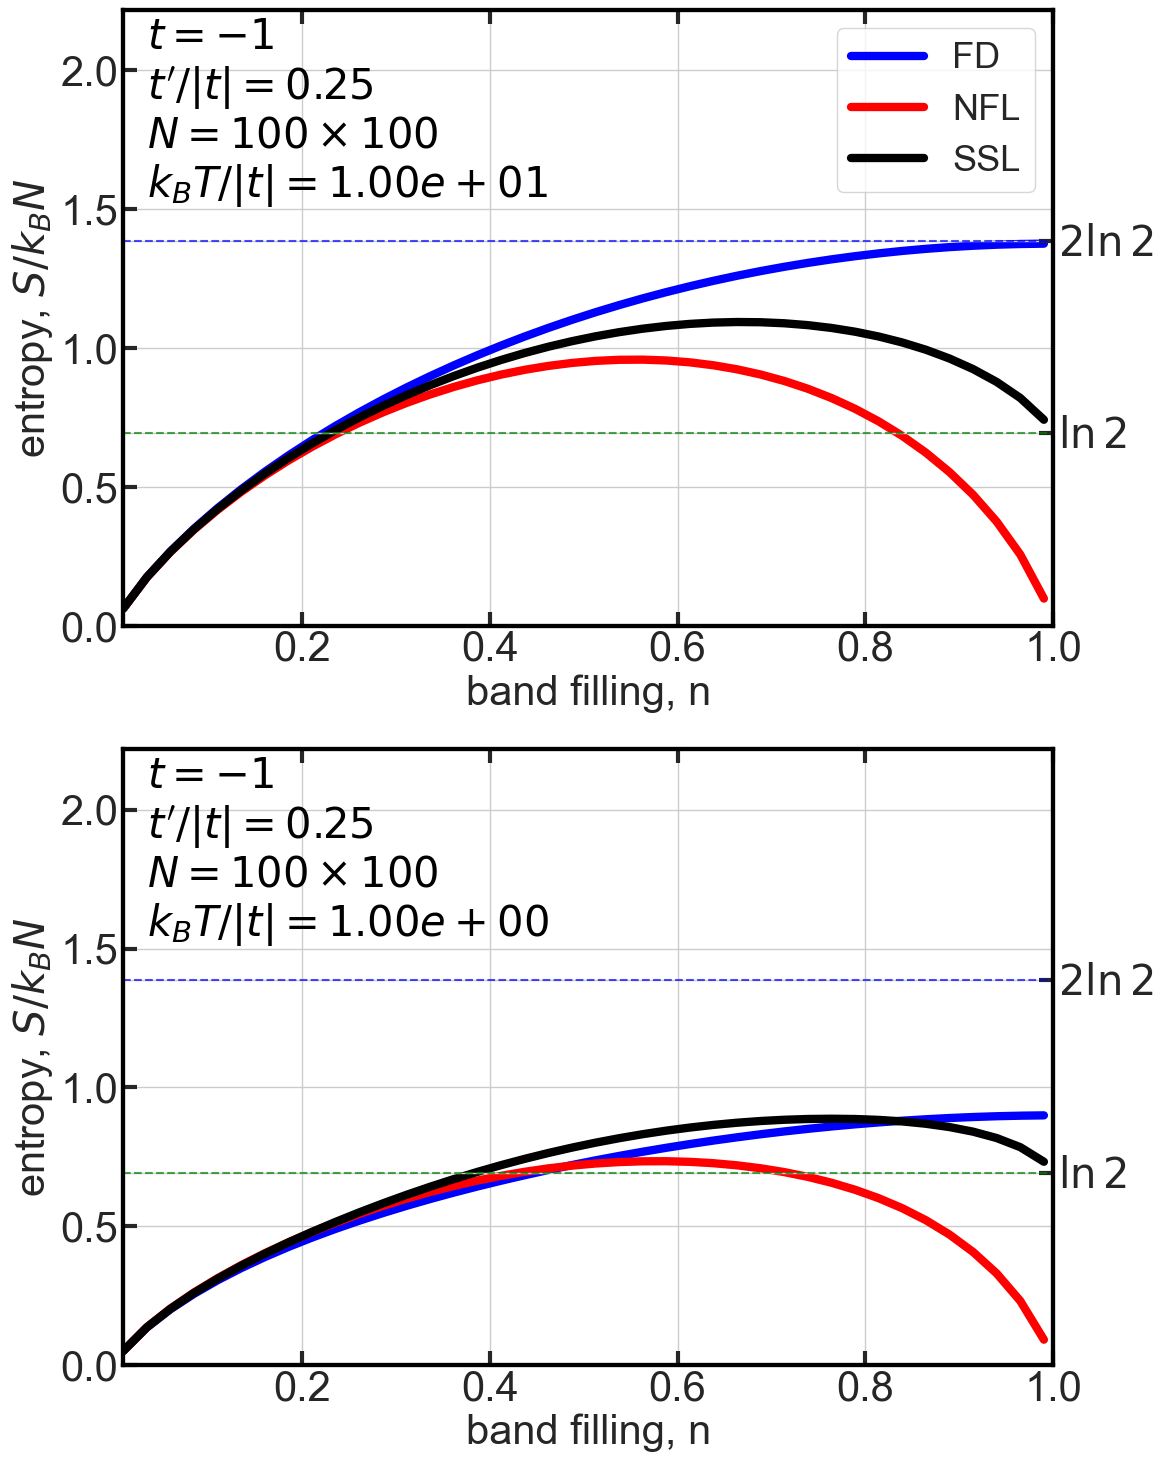

In [86]:
H_a_plot = H_a[0] 
#distro = ["FD","FLB","NFL","NFL_REWORKED", "NFLB", "SSL", "HUBBARD"]
# Plot
distro = ["FD","NFL_REWORKED", "NFL_old","SSL"]
distro = ["FD","NFL_REWORKED", "SSL"]
legend_loc = "center left"
PlotConfig = sp.PlotConfig(legend_loc=legend_loc)

plotter = sp.ScientificPlotter(config=PlotConfig)
plotter.plot_scalar_result(
    results=entropy_df,
    x_param="n",
    y_col="entropy",
    y_label=r"entropy, $S / k_B N$",
    fixed_params={"H_a": H_a_plot},
    distros=distro,
    subplots_param="kBT",
    subplots_vals=kBT,
    cols=1,
    figsize=(12, 8.8),
    show_log_vals=True,
    ylims=(0, 2.6),
    U=U,
    xlims=(0.01, 1)
)
#entropy_df_plot = entropy_df.rename(
#    index={
#        "NFL": "NFL_old",
#        "NFL_REWORKED": "NFL"
#    },
#    level="distro"
#)
fig = plt.gcf()
#for ax in fig.axes:
handles, labels = fig.axes[0].get_legend_handles_labels()
#if not handles:
#    continue
label_map = {
    "NFL_REWORKED": "NFL",
}
new_labels = [label_map.get(lbl, lbl) for lbl in labels]
fig.axes[0].legend(handles, new_labels, loc="upper right", fontsize=26)
plt.show()


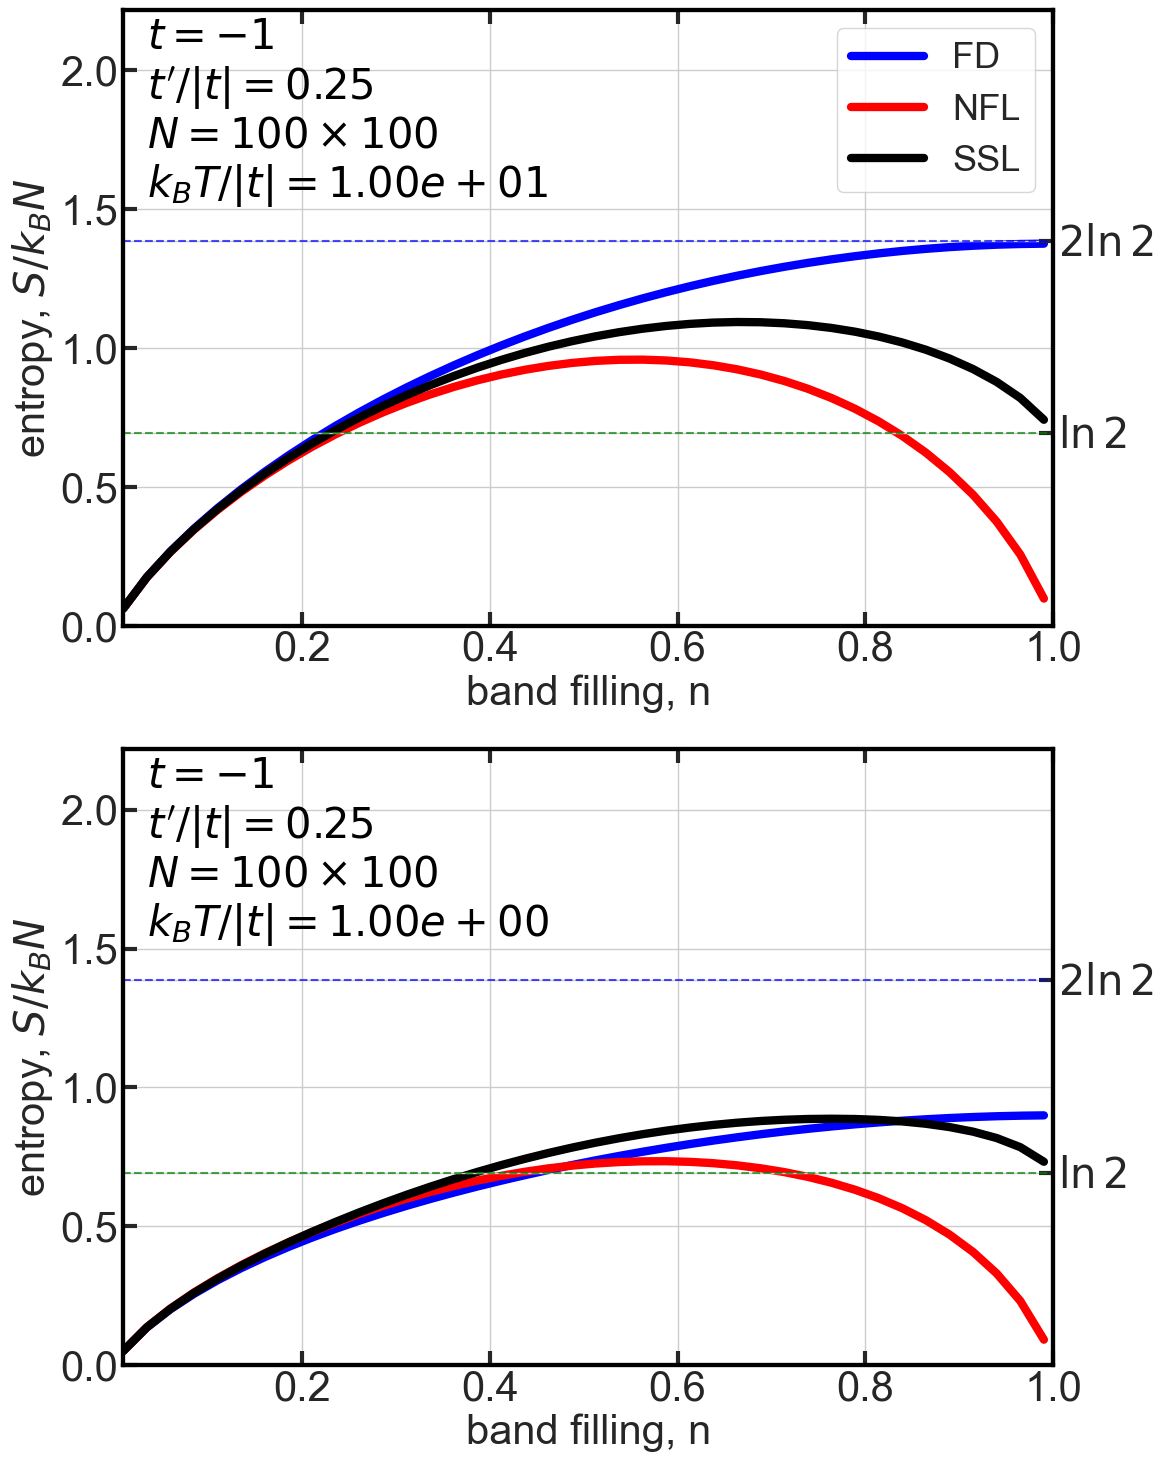

In [88]:
H_a_plot = H_a[0] 
#distro = ["FD","FLB","NFL","NFL_REWORKED", "NFLB", "SSL", "HUBBARD"]
# Plot
distro = ["FD","NFL", "NFL_old","SSL"]
distro = ["FD","NFL_REWORKED","SSL"]
#entropy_df_plot = entropy_df.rename(
#    index={
#        "NFL": "NFL_old",
#        "NFL_REWORKED": "NFL"
#    },
#    level="distro"
#)
legend_loc = "center left"
PlotConfig = sp.PlotConfig(legend_loc=legend_loc)

plotter = sp.ScientificPlotter(config=PlotConfig)
plotter.plot_scalar_result(
    results=entropy_df,
    x_param="n",
    y_col="entropy",
    y_label=r"entropy, $S / k_B N$",
    fixed_params={"H_a": H_a_plot},
    distros=distro,
    subplots_param="kBT",
    subplots_vals=kBT,
    cols=1,
    figsize=(12, 8.8),
    show_log_vals=True,
    ylims=(0, 2.6),
    U=U,
    xlims=(0.01, 1)
)
fig = plt.gcf()
#for ax in fig.axes:
handles, labels = fig.axes[0].get_legend_handles_labels()
#if not handles:
#    continue
label_map = {
    "NFL_REWORKED": "NFL",
}
new_labels = [label_map.get(lbl, lbl) for lbl in labels]
fig.axes[0].legend(handles, new_labels, loc="upper right", fontsize=26)
plt.show()

plt.show()

In [7]:
# Band filling values
kBT_min = 0.01
kBT_max = 0.99
kBT_count = 40

n = [0.8, 0.99]
H_a = [0.]
U = 100.0


distros = [DistType.FD, DistType.FLB, DistType.NFL, DistType.NFL_REWORKED, DistType.NFLB, DistType.SSL, DistType.HUBBARD]  # ND
kBT  = np.linspace(kBT_min, kBT_max, kBT_count, dtype=np.float64)  # NN
n = np.array(n, dtype=np.float64)  # NB
H_a = np.array(H_a, dtype=np.float64) # NH

## Entropy(T)

In [8]:
py_opts = brent_defaults(
    abs_tol=1e-9, 
    rel_tol=1e-6, 
    expand_factor=2.0,
    initial_step=1.0,  
    max_expands=164,
    max_iters=5000      
)
native_opts= py_opts.to_qss()

mu_df = chemical_potential(
    distros=distros,
    n_vals=n,
    kBT_vals=kBT,
    H_a_vals=H_a,
    N=N,
    E=e_k,
    U=U,
    solver_opts=native_opts,
    x0=-1.0,
    a0=-5.0,
    b0=5.0,
)

In [9]:
entropy_df = entropy(df=mu_df, E=e_k, U=U)

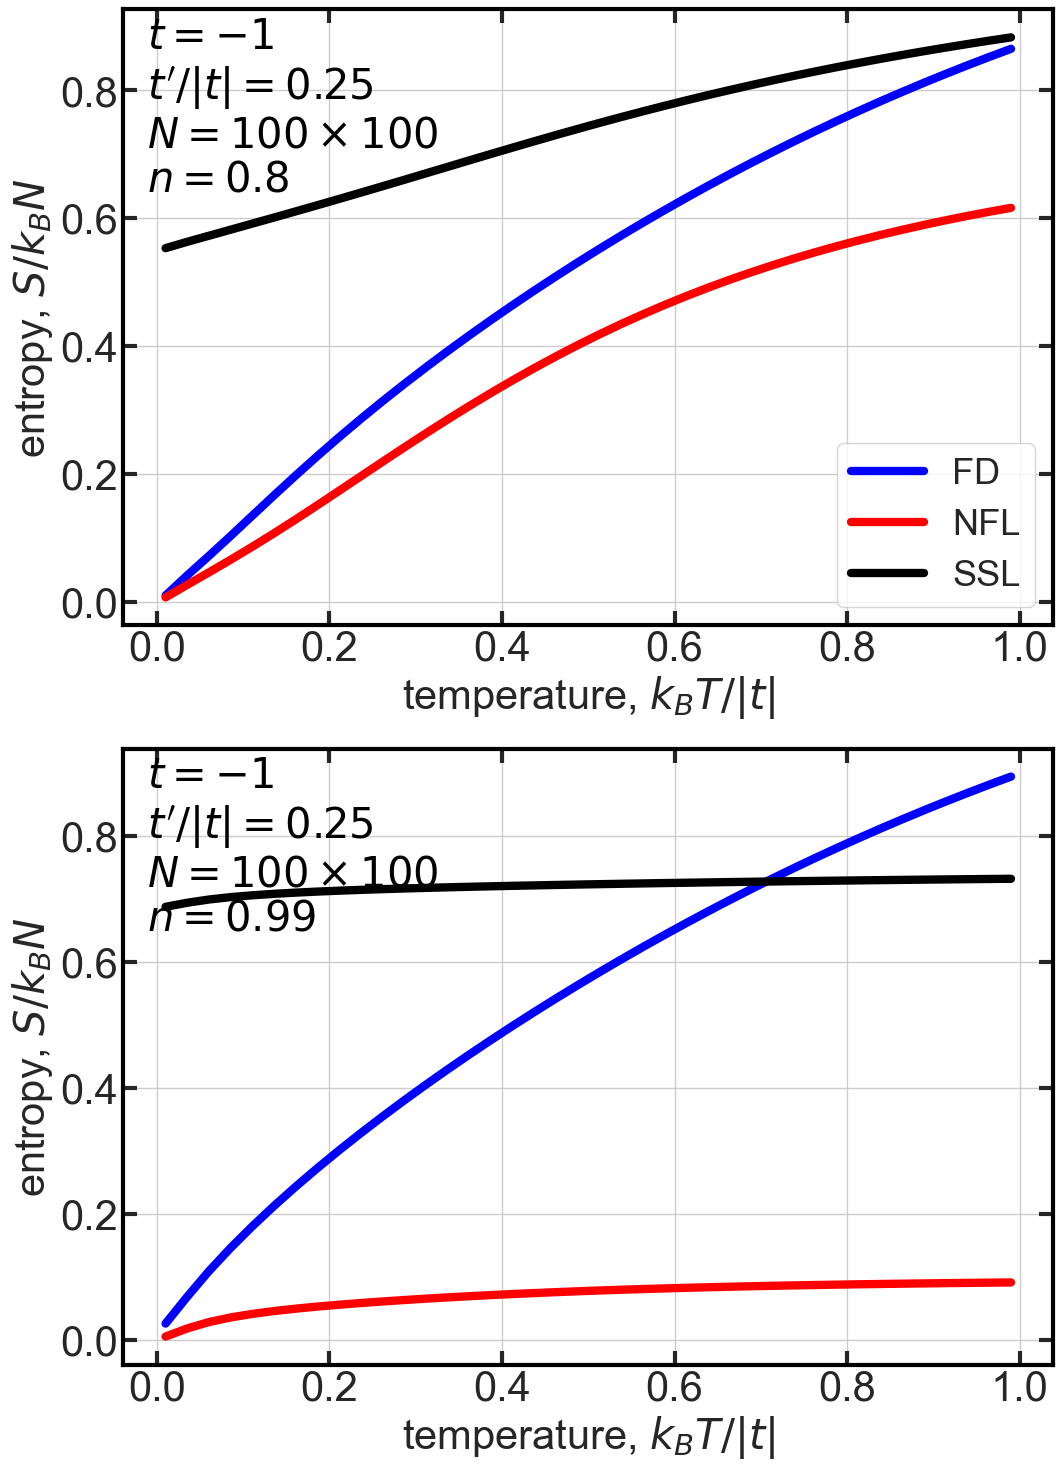

In [10]:
H_a_plot = H_a[0] 
#distro = ["FD","FLB","NFL","NFL_REWORKED", "NFLB", "SSL", "HUBBARD"]
# Plot
#distro = ["FD","NFL", "NFL_old","SSL"]
distro = ["FD","NFL_REWORKED","SSL"]
#entropy_df_plot = entropy_df.rename(
#    index={
#        "NFL": "NFL_old",
#        "NFL_REWORKED": "NFL"
#    },
#    level="distro"
#)
legend_loc = "center right"
PlotConfig = sp.PlotConfig(legend_loc=legend_loc)

plotter = sp.ScientificPlotter(config=PlotConfig)
plotter.plot_scalar_result(
    results=entropy_df,
    x_param="k_BT",
    y_col="entropy",
    y_label=r"entropy, $S / k_B N$",
    fixed_params={"H_a": H_a_plot},
    distros=distro,
    subplots_param="n",
    subplots_vals=n,
    cols=1,
    figsize=(12, 8.8),
    # show_log_vals=True,
    # ylims=(0, 2.6),
    U=U,
    # xlims=(0.01, 1)
)
fig = plt.gcf()
#for ax in fig.axes:
handles, labels = fig.axes[0].get_legend_handles_labels()
#if not handles:
#    continue
label_map = {
    "NFL_REWORKED": "NFL",
}
new_labels = [label_map.get(lbl, lbl) for lbl in labels]
fig.axes[0].legend(handles, new_labels, loc="lower right", fontsize=26)
plt.show()

plt.show()

# Porównanie

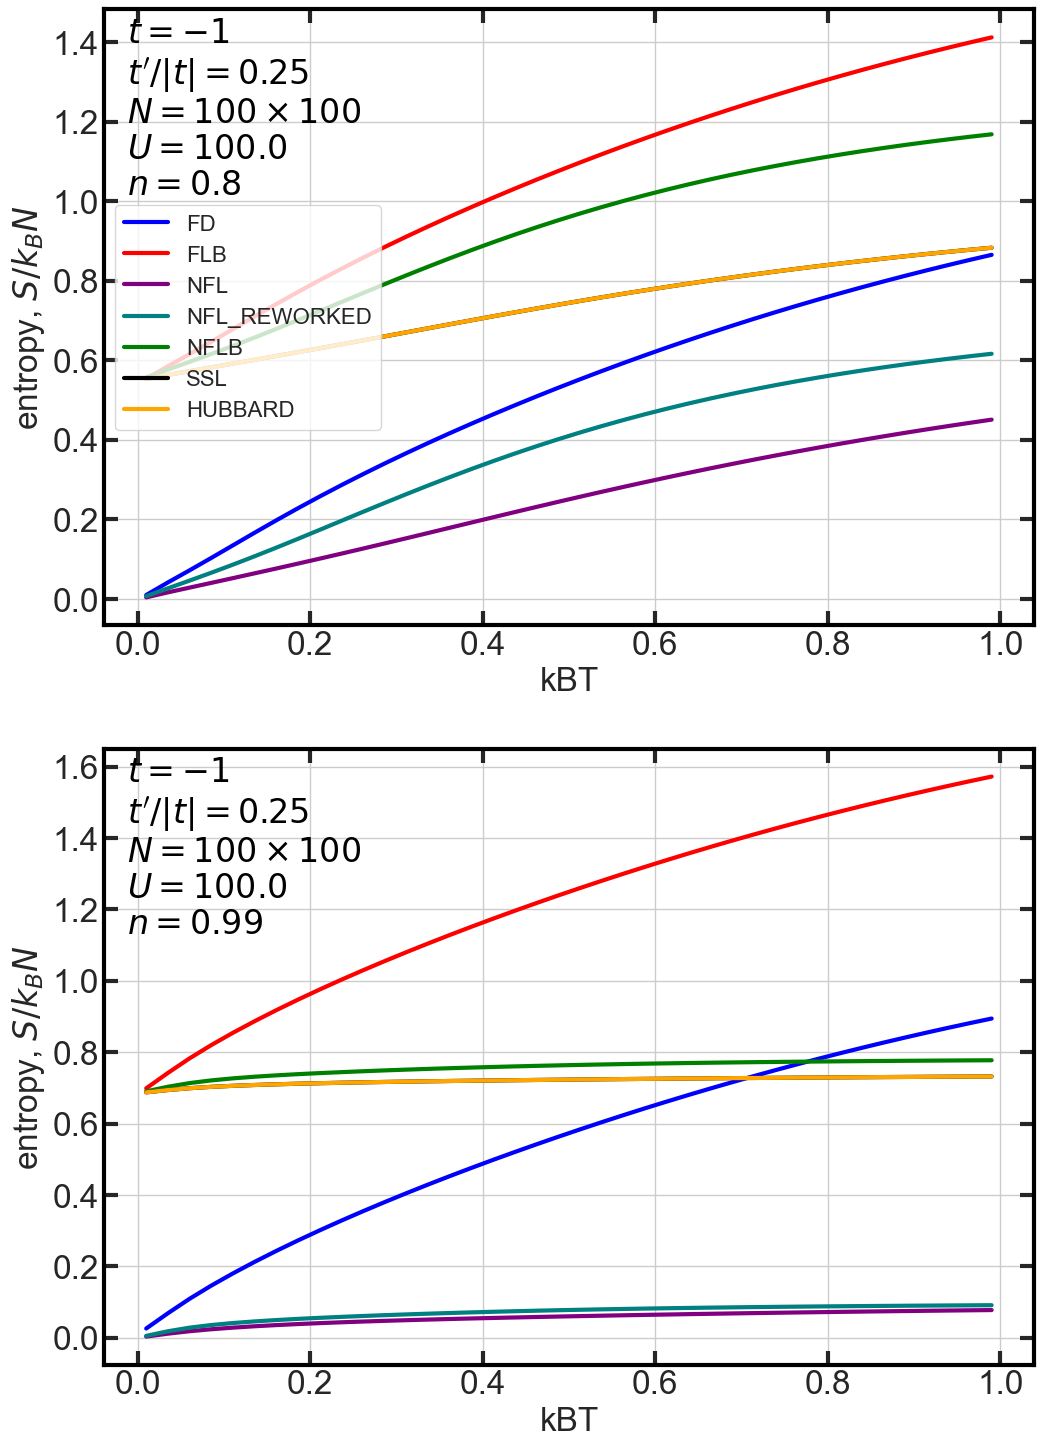

In [88]:
H_a_plot = H_a[0] 
distro = ["FD","FLB","NFL","NFL_REWORKED", "NFLB", "SSL", "HUBBARD"]
# Plot
#distro = ["FD","NFL", "NFL_old","SSL"]
entropy_df_plot = entropy_df.rename(
    index={
        "NFL": "NFL_old",
        "NFL_REWORKED": "NFL"
    },
    level="distro"
)
legend_loc = "center left"
PlotConfig = sp.PlotConfig(legend_loc=legend_loc)

plotter = sp.ScientificPlotter(config=PlotConfig)
plotter.plot_scalar_result(
    results=entropy_df,
    x_param="kBT",
    y_col="entropy",
    y_label=r"entropy, $S / k_B N$",
    fixed_params={"H_a": H_a_plot},
    distros=distro,
    subplots_param="n",
    subplots_vals=n,
    cols=1,
    figsize=(12, 8.8),
    # show_log_vals=True,
    # ylims=(0, 2.6),
    U=U,
    # xlims=(0.01, 1)
)
plt.show()

# Wykresy Final APPB

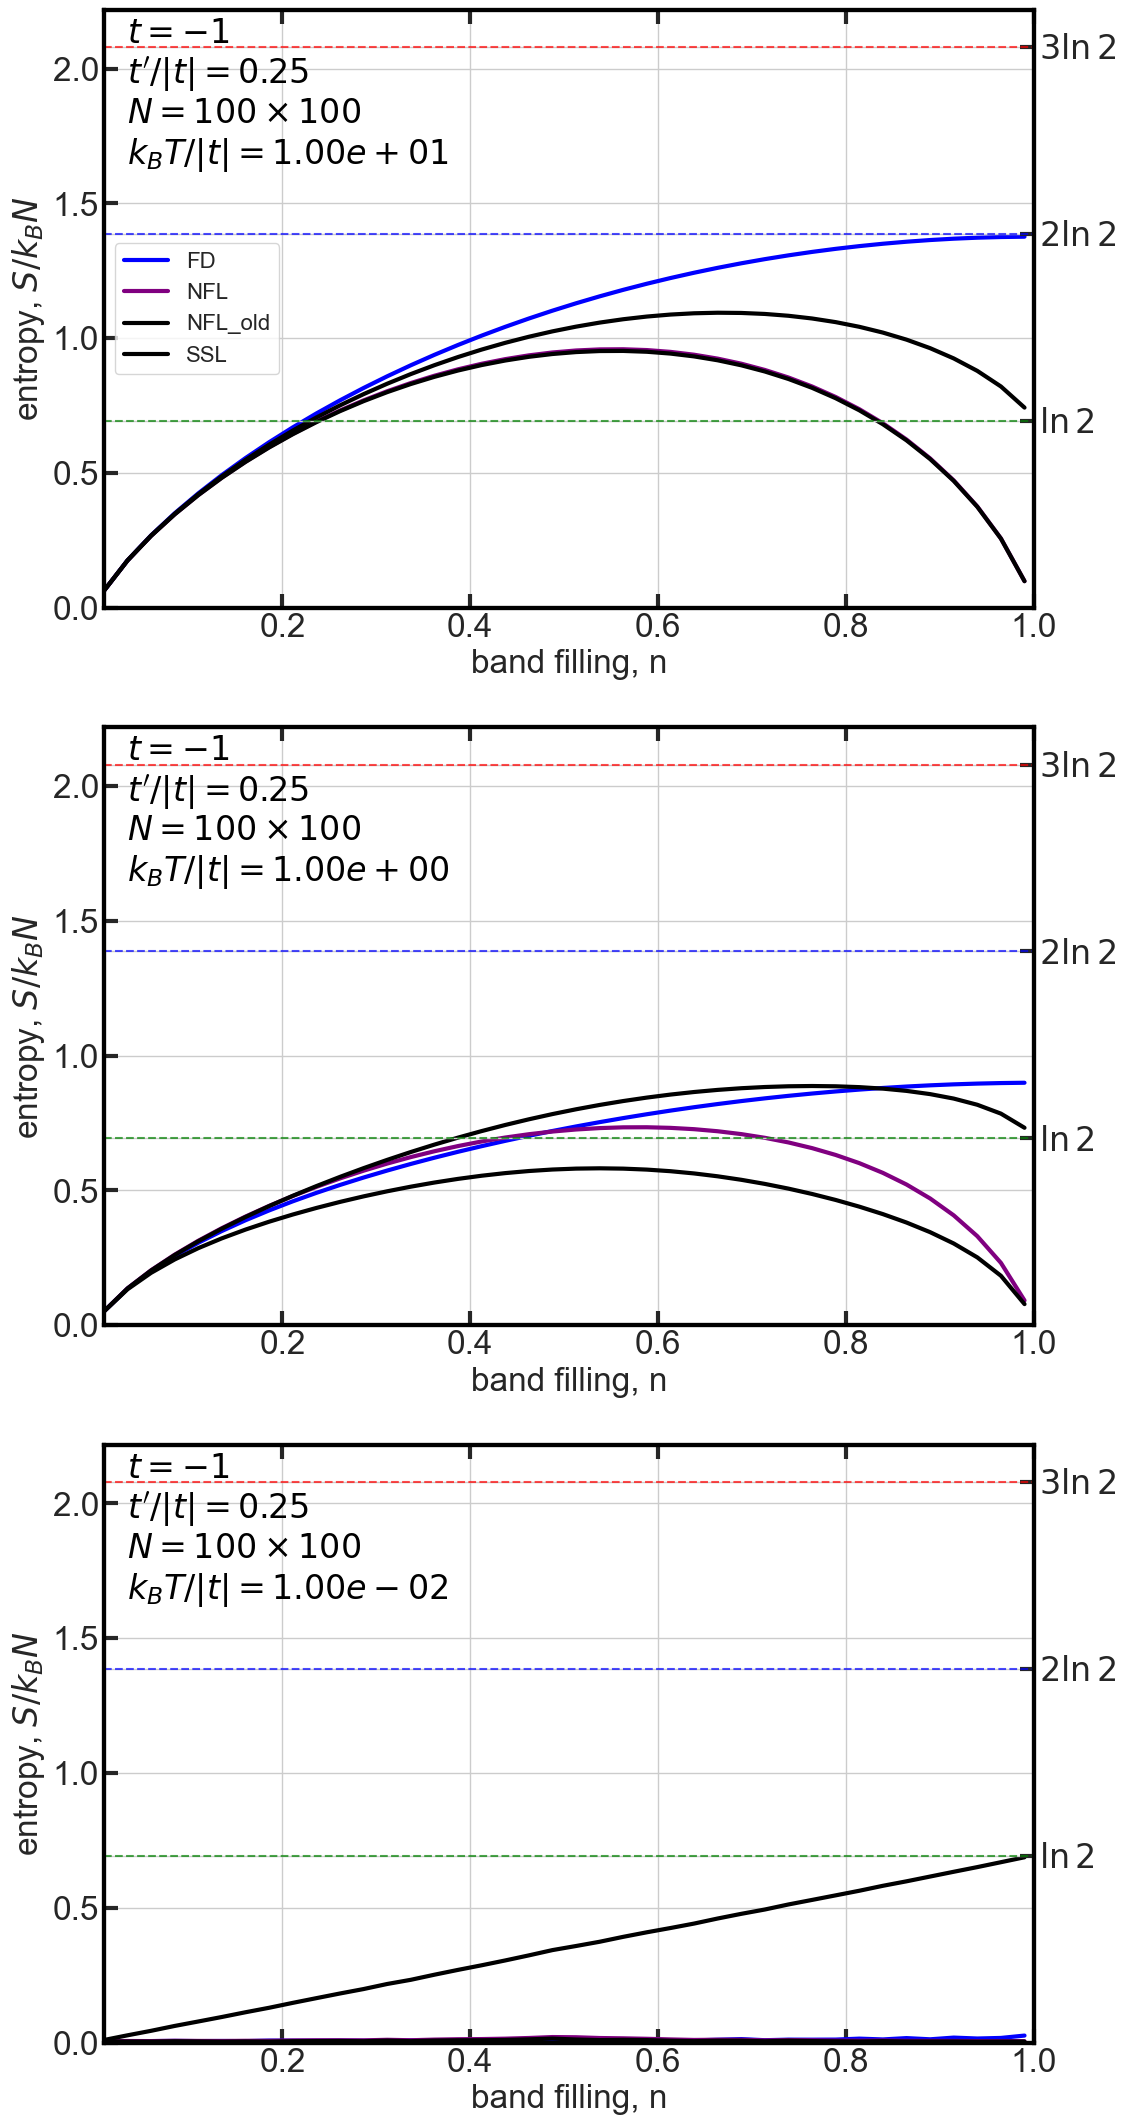

In [9]:
H_a_plot = H_a[0] 
#distro = ["FD","FLB","NFL","NFL_REWORKED", "NFLB", "SSL", "HUBBARD"]
# Plot
distro = ["FD","NFL", "NFL_old","SSL"]
entropy_df_plot = entropy_df.rename(
    index={
        "NFL": "NFL_old",
        "NFL_REWORKED": "NFL"
    },
    level="distro"
)
legend_loc = "center left"
PlotConfig = sp.PlotConfig(legend_loc=legend_loc)

plotter = sp.ScientificPlotter(config=PlotConfig)
plotter.plot_scalar_result(
    results=entropy_df_plot,
    x_param="n",
    y_col="entropy",
    y_label=r"entropy, $S / k_B N$",
    fixed_params={"H_a": H_a_plot},
    distros=distro,
    subplots_param="kBT",
    subplots_vals=kBT,
    cols=1,
    figsize=(12, 8.8),
    show_log_vals=True,
    ylims=(0, 2.6),
    U=U,
    xlims=(0.01, 1)
)
plt.show()



In [39]:
H_a_plot = H_a[0] 
distro = ["FD","FLB","NFL","NFL_REWORKED", "NFLB", "SSL", "HUBBARD"]
# Plot
#entropy_df_plot = entropy_df.rename(
#    index={
#        "NFL": "NFL_old",
#        "NFL_REWORKED": "NFL"
#    },
#    level="distro"
#)
distro = ["FD","NFL_REWORKED", "NFL_old","SSL"]

legend_loc = "center left"
PlotConfig = sp.PlotConfig(legend_loc=legend_loc)

plotter = sp.ScientificPlotter(config=PlotConfig)
plotter.plot_scalar_result(
    results=entropy_df_plot,
    x_param="kBT",
    y_col="entropy",
    y_label=r"entropy, $S / k_B N$",
    fixed_params={"H_a": H_a_plot},
    distros=distro,
    subplots_param="n",
    subplots_vals=n,
    cols=1,
    figsize=(12, 8.8),
    # show_log_vals=True,
    # ylims=(0, 2.6),
    U=U,
    # xlims=(0.01, 1)
)
plt.show()

# Wersja bez OLD

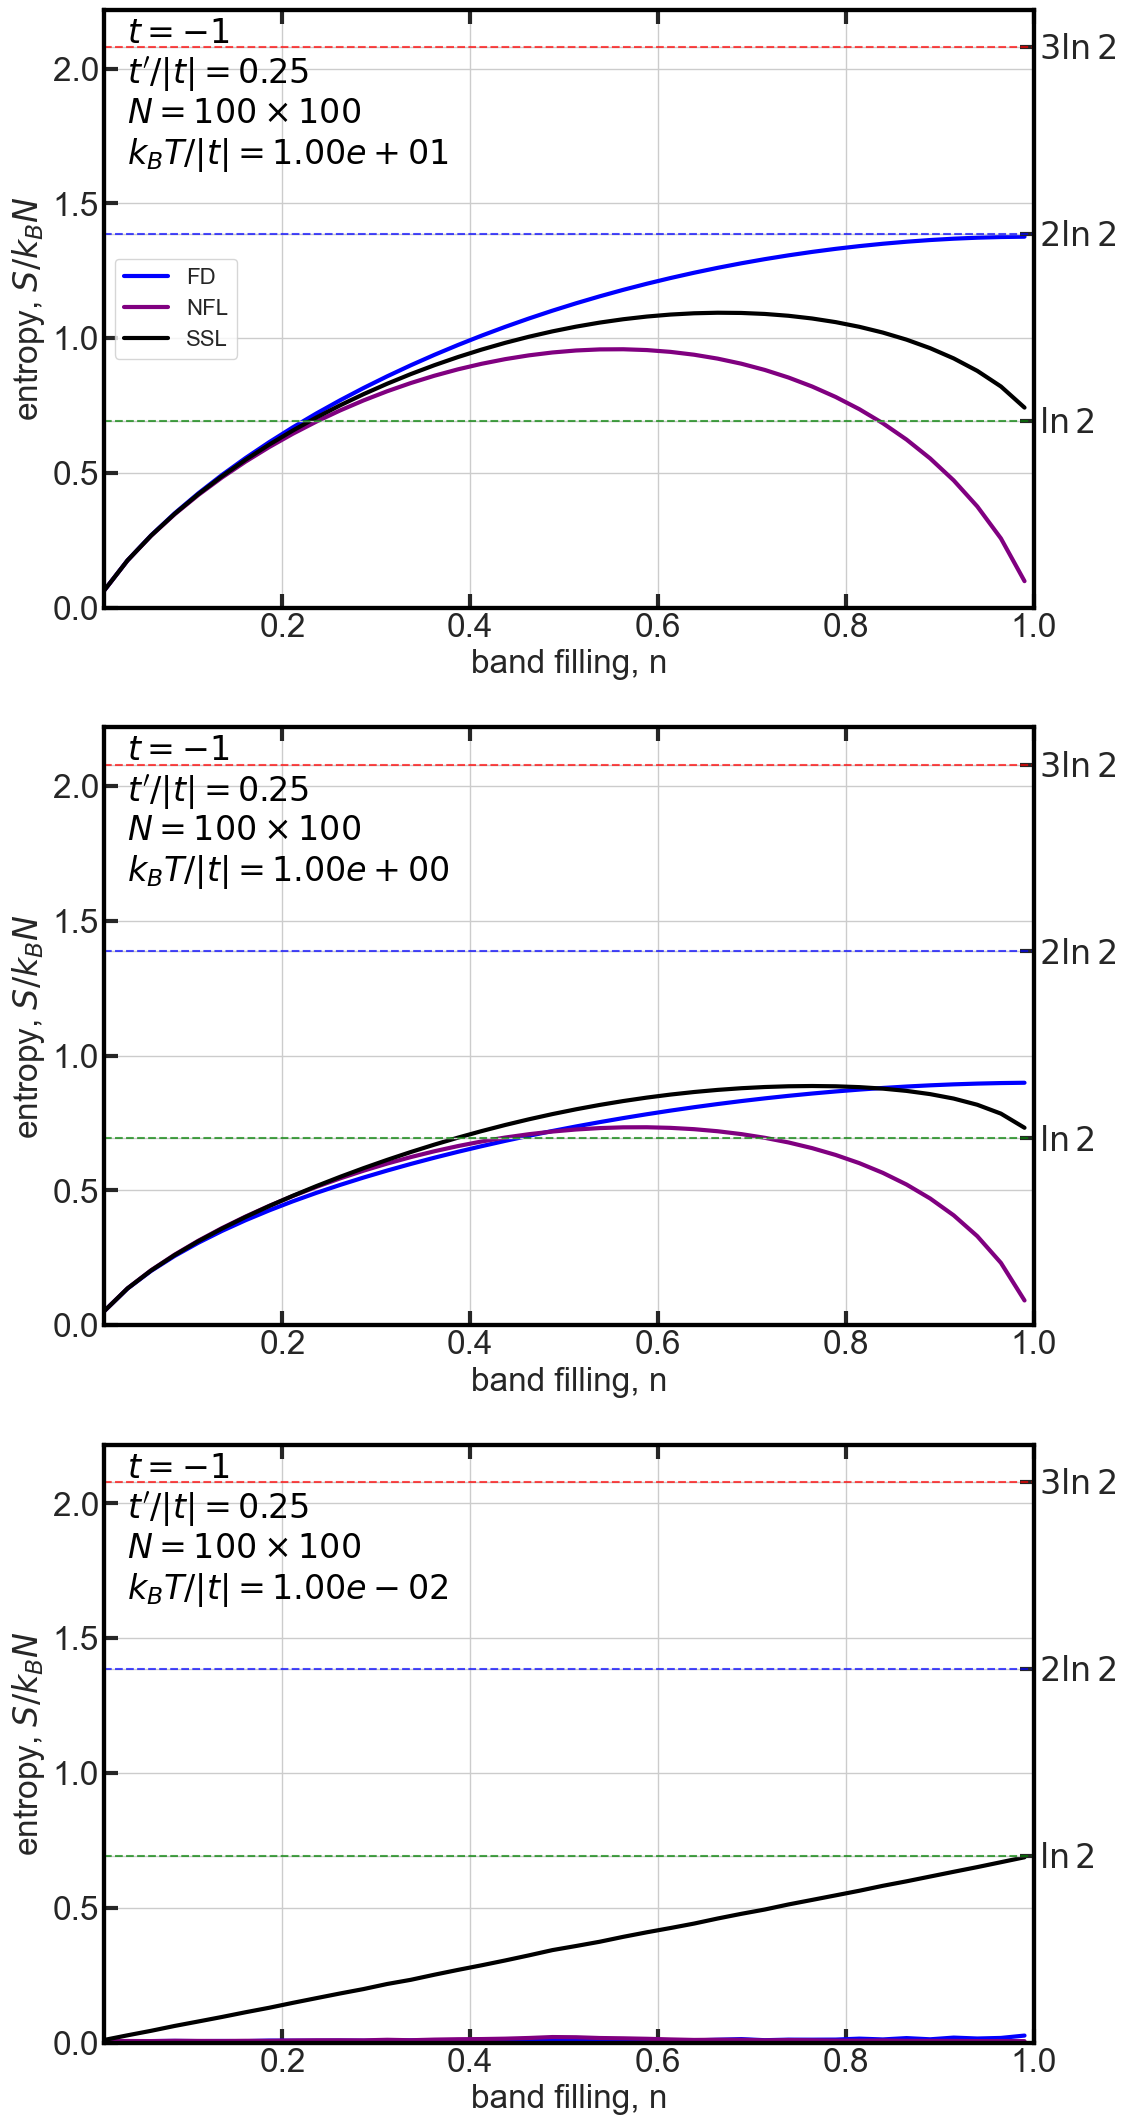

In [8]:
H_a_plot = H_a[0] 
#distro = ["FD","FLB","NFL","NFL_REWORKED", "NFLB", "SSL", "HUBBARD"]
# Plot
distro = ["FD","NFL","SSL"]
entropy_df_plot = entropy_df.rename(
    index={
        "NFL": "NFL_old",
        "NFL_REWORKED": "NFL"
    },
    level="distro"
)
legend_loc = "center left"
PlotConfig = sp.PlotConfig(legend_loc=legend_loc)

plotter = sp.ScientificPlotter(config=PlotConfig)
plotter.plot_scalar_result(
    results=entropy_df_plot,
    x_param="n",
    y_col="entropy",
    y_label=r"entropy, $S / k_B N$",
    fixed_params={"H_a": H_a_plot},
    distros=distro,
    subplots_param="kBT",
    subplots_vals=kBT,
    cols=1,
    figsize=(12, 8.8),
    show_log_vals=True,
    ylims=(0, 2.6),
    U=U,
    xlims=(0.01, 1)
)
plt.show()



In [55]:
H_a_plot = H_a[0] 
distro = ["FD","FLB","NFL","NFL_REWORKED", "NFLB", "SSL", "HUBBARD"]
# Plot
entropy_df_plot = entropy_df.rename(
    index={
        "NFL": "NFL_old",
        "NFL_REWORKED": "NFL"
    },
    level="distro"
)
distro = ["FD","NFL", "SSL"]

legend_loc = "center left"
PlotConfig = sp.PlotConfig(legend_loc=legend_loc)

plotter = sp.ScientificPlotter(config=PlotConfig)
plotter.plot_scalar_result(
    results=entropy_df_plot,
    x_param="k_BT",
    y_col="entropy",
    y_label=r"entropy, $S / k_B N$",
    fixed_params={"H_a": H_a_plot},
    distros=distro,
    subplots_param="n",
    subplots_vals=n,
    cols=1,
    figsize=(12, 8.8),
    # show_log_vals=True,
    # ylims=(0, 2.6),
    U=U,
    # xlims=(0.01, 1)
)
plt.show()